# 01 — Exploratory Data Analysis (RSNA Bone Age)

In [1]:
import sys; sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import config
sns.set_theme(style="whitegrid")
df = pd.read_csv(config.TRAIN_CSV)
print(df.shape); df.head()

(12611, 3)


,id,boneage,male
0,1377,180,False
1,1378,12,False
2,1379,94,False
3,1380,120,True
4,1381,82,False


In [2]:
df.describe(include="all")

,id,boneage,male
count,12611.000000,12611.000000,12611
unique,NaN,NaN,2
top,NaN,NaN,True
freq,NaN,NaN,6833
mean,8537.653001,127.320752,NaN
std,4108.763993,41.182021,NaN
min,1377.000000,1.000000,NaN
25%,5074.500000,96.000000,NaN
50%,8565.000000,132.000000,NaN
75%,12091.500000,156.000000,NaN


## Basic checks

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12611 entries, 0 to 12610
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   id       12611 non-null  int64
 1   boneage  12611 non-null  int64
 2   male     12611 non-null  bool 
dtypes: bool(1), int64(2)
memory usage: 209.5 KB


In [4]:
df.tail()

,id,boneage,male
12606,15605,50,False
12607,15606,113,False
12608,15608,55,False
12609,15609,150,True
12610,15610,132,True


In [5]:
print("shape:", df.shape)
print("missing values:", df.isnull().sum().to_dict())
print("duplicate rows:", df.duplicated().sum(), "| duplicate ids:", df["id"].duplicated().sum())
print("unique values:", df.nunique().to_dict())

shape: (12611, 3)
missing values: {'id': 0, 'boneage': 0, 'male': 0}
duplicate rows: 0 | duplicate ids: 0
unique values: {'id': 12611, 'boneage': 160, 'male': 2}


In [6]:
print(df["boneage"].value_counts().head(10))
print("skewness:", round(df["boneage"].skew(), 3), "| kurtosis:", round(df["boneage"].kurt(), 3))

boneage
156    1113
132    1084
120     992
168     892
162     682
150     678
144     657
138     529
94      492
106     478
Name: count, dtype: int64
skewness: -0.475 | kurtosis: -0.237


## Bone age distribution

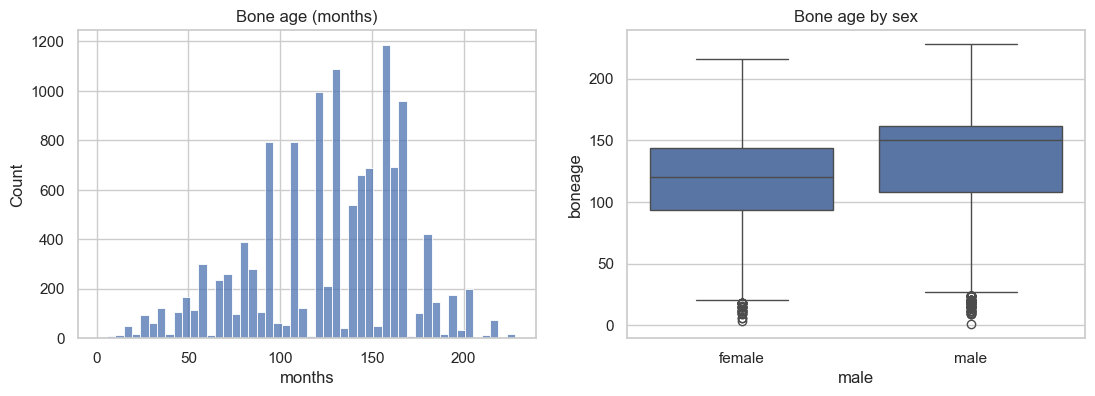

        count   mean   std  min    25%    50%    75%    max
male                                                       
False  5778.0  117.9  37.9  4.0   94.0  120.0  144.0  216.0
True   6833.0  135.3  42.1  1.0  108.0  150.0  162.0  228.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["boneage"], bins=50, ax=axes[0]); axes[0].set(title="Bone age (months)", xlabel="months")
sns.boxplot(data=df, x="male", y="boneage", ax=axes[1]); axes[1].set(title="Bone age by sex", xticks=[0, 1], xticklabels=["female", "male"])
plt.show()
print(df.groupby("male")["boneage"].describe().round(1))

## Sex balance

In [8]:
print(df["male"].value_counts(normalize=True).rename({True: "male", False: "female"}).round(3))

male
male      0.542
female    0.458
Name: proportion, dtype: float64


## Image sizes

         width   height
count  12611.0  12611.0
mean    1319.0   1664.0
std      314.0    367.0
min      521.0    640.0
25%     1113.0   1421.0
50%     1277.0   1624.0
75%     1476.0   1846.0
max     3001.0   2989.0
aspect ratio (h/w): {'count': 12611.0, 'mean': 1.28, 'std': 0.17, 'min': 0.64, '25%': 1.17, '50%': 1.26, '75%': 1.37, 'max': 2.16}


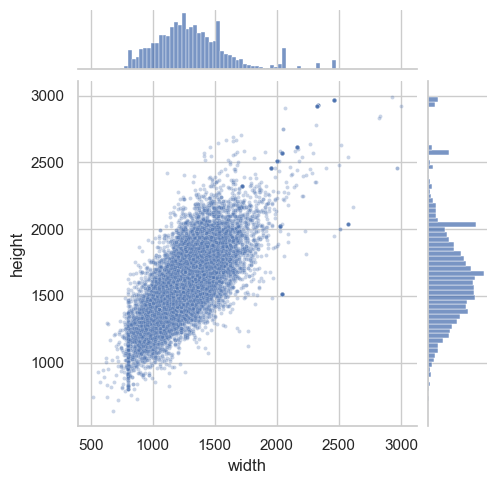

In [9]:
sizes = np.array([Image.open(config.TRAIN_IMG_DIR / f"{i}.png").size for i in df["id"]])
df["width"], df["height"] = sizes[:, 0], sizes[:, 1]
print(df[["width", "height"]].describe().round(0))
print("aspect ratio (h/w):", (df.height / df.width).describe().round(2).to_dict())
sns.jointplot(data=df, x="width", y="height", s=8, alpha=0.3, height=5); plt.show()

## Sample images across ages

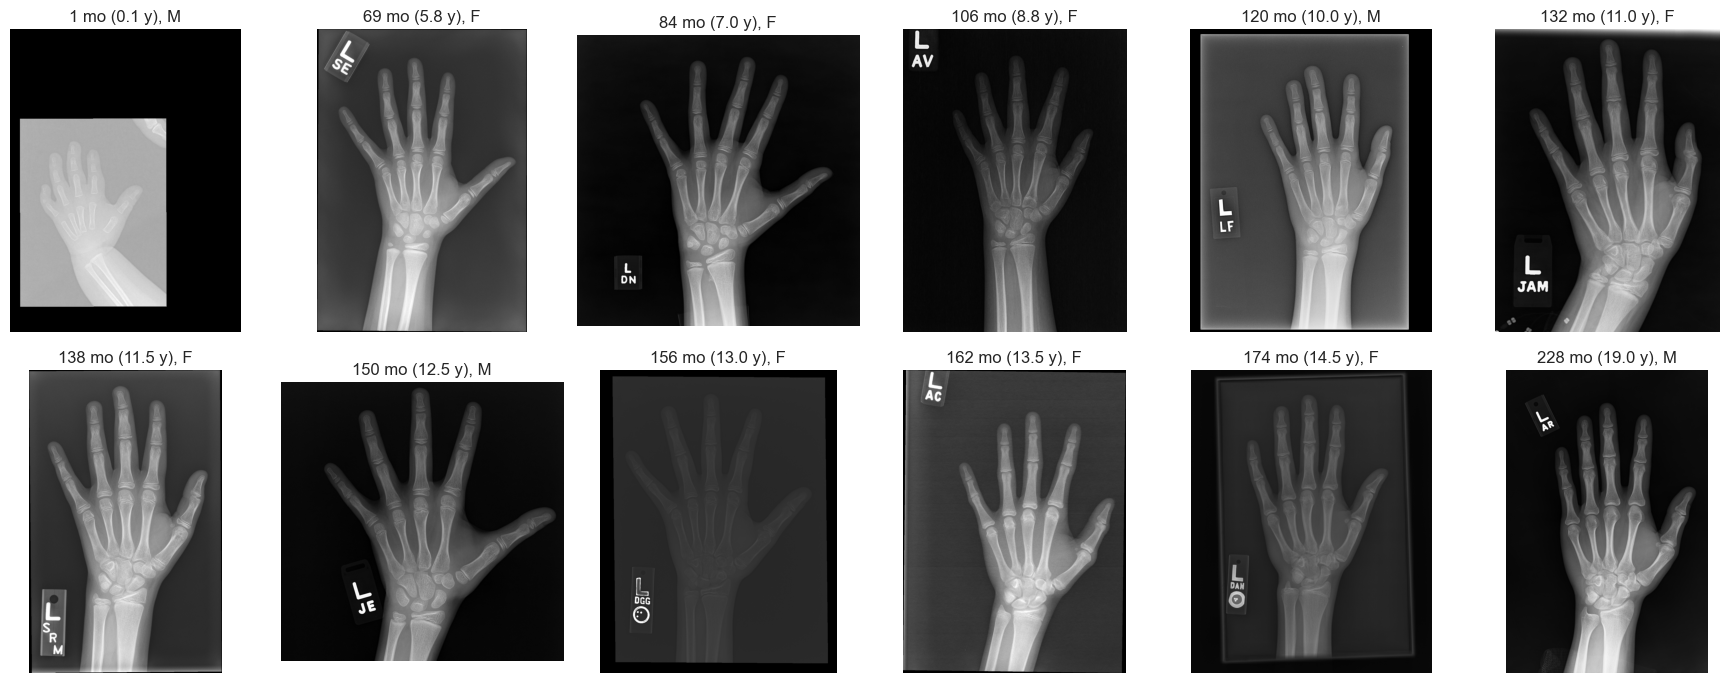

In [10]:
picks = df.sort_values("boneage").iloc[np.linspace(0, len(df) - 1, 12).astype(int)]
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
for ax, (_, r) in zip(axes.ravel(), picks.iterrows()):
    ax.imshow(cv2.imread(str(config.TRAIN_IMG_DIR / f"{r.id}.png"), cv2.IMREAD_GRAYSCALE), cmap="gray")
    ax.set_title(f"{r.boneage} mo ({r.boneage / 12:.1f} y), {'M' if r.male else 'F'}"); ax.axis("off")
plt.tight_layout(); plt.show()

## Image quality: brightness and contrast

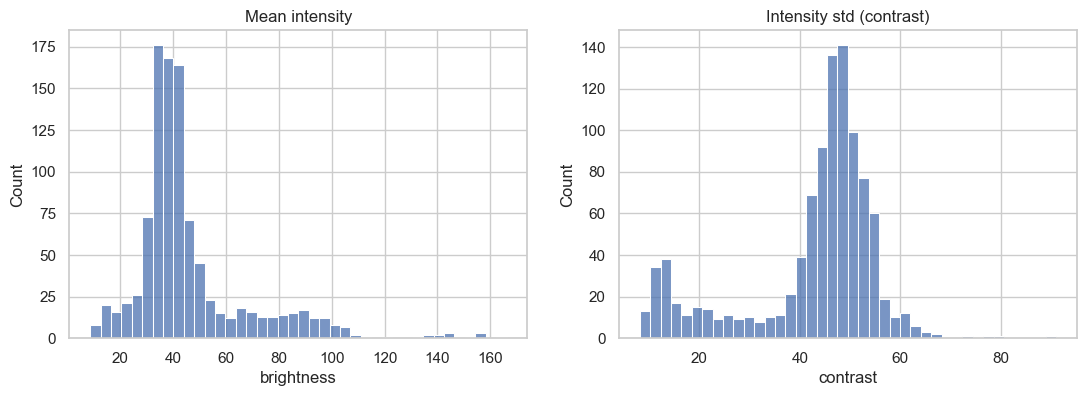

       brightness  contrast
count      1000.0    1000.0
mean         46.0      42.4
std          22.3      13.4
min           8.5       8.1
25%          34.4      40.6
50%          39.9      46.6
75%          48.5      50.3
max         166.2      91.0


In [11]:
sample = df.sample(1000, random_state=config.SEED).copy()
imgs = [cv2.imread(str(config.TRAIN_IMG_DIR / f"{i}.png"), cv2.IMREAD_GRAYSCALE) for i in sample["id"]]
sample["brightness"] = [im.mean() for im in imgs]
sample["contrast"] = [im.std() for im in imgs]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(sample["brightness"], bins=40, ax=axes[0]).set(title="Mean intensity")
sns.histplot(sample["contrast"], bins=40, ax=axes[1]).set(title="Intensity std (contrast)")
plt.show()
print(sample[["brightness", "contrast"]].describe().round(1))

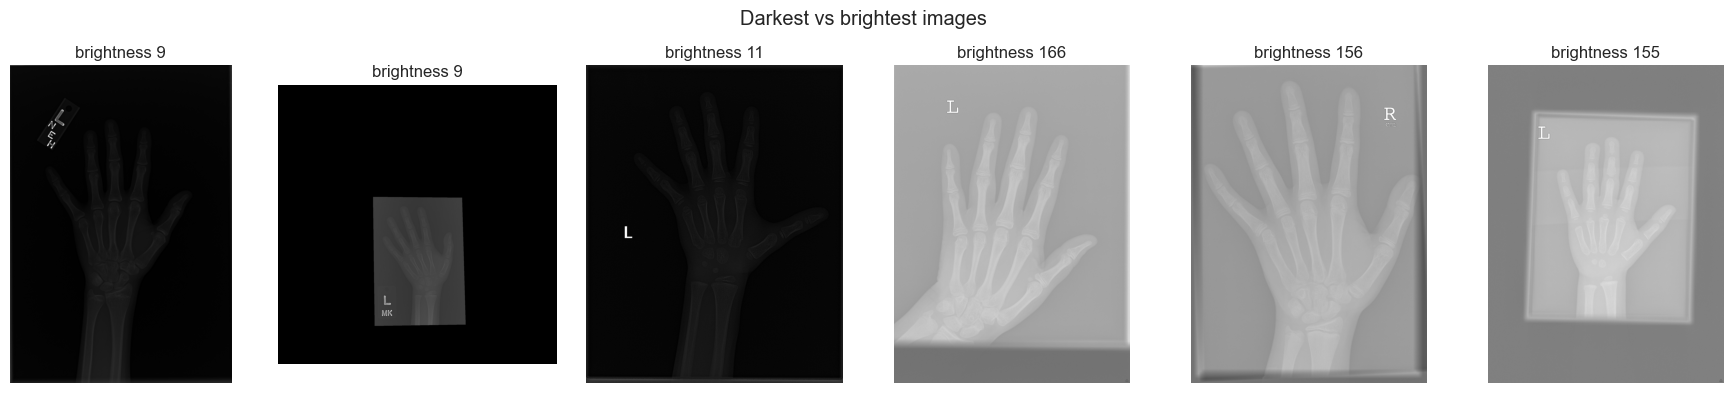

In [12]:
fig, axes = plt.subplots(1, 6, figsize=(18, 4))
ext = pd.concat([sample.nsmallest(3, "brightness"), sample.nlargest(3, "brightness")])
for ax, (_, r) in zip(axes, ext.iterrows()):
    ax.imshow(cv2.imread(str(config.TRAIN_IMG_DIR / f"{r.id}.png"), cv2.IMREAD_GRAYSCALE), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"brightness {r.brightness:.0f}"); ax.axis("off")
plt.suptitle("Darkest vs brightest images"); plt.tight_layout(); plt.show()

## Correlation map

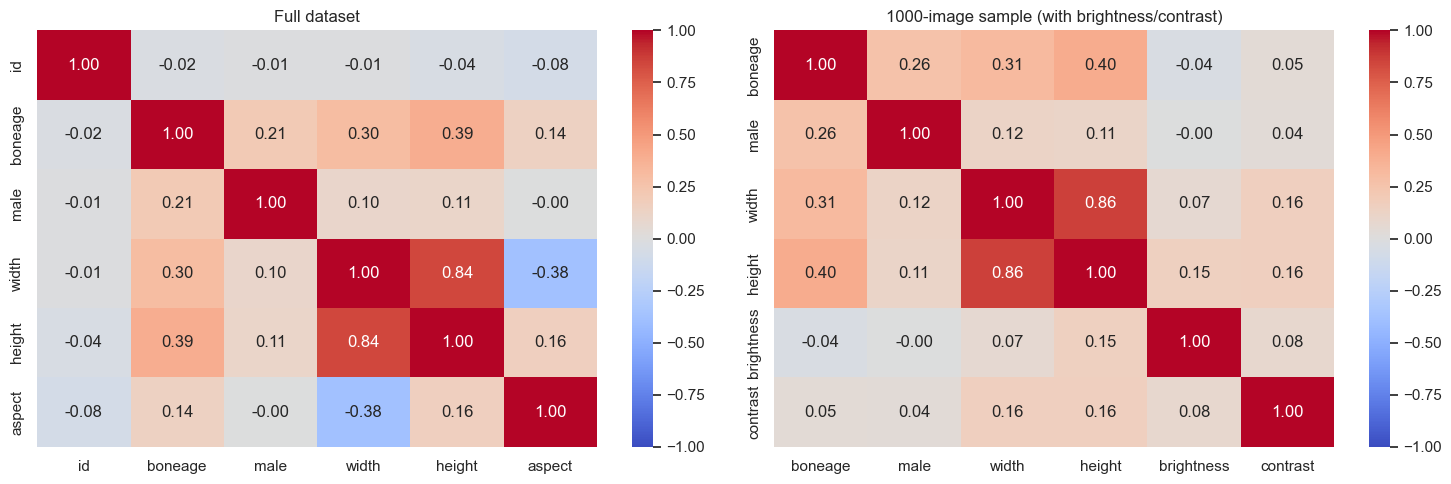

In [13]:
df["aspect"] = df["height"] / df["width"]
num = df[["id", "boneage", "male", "width", "height", "aspect"]].astype(float)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0]).set(title="Full dataset")
sample["width"] = df.loc[sample.index, "width"]; sample["height"] = df.loc[sample.index, "height"]
s = sample[["boneage", "male", "width", "height", "brightness", "contrast"]].astype(float)
sns.heatmap(s.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1]).set(title="1000-image sample (with brightness/contrast)")
plt.tight_layout(); plt.show()

## Bulgular (Findings)
- **12.611 görüntü**, eksik değer yok. Kemik yaşı 1–228 ay, ortalama **127 ay (~10.6 yaş)**, std **41 ay**. Dağılım sola çarpık: 5 yaş altı örnek az.
- **Cinsiyet**: %54 erkek / %46 kız (dengeli sayılır). Erkeklerin ortalama kemik yaşı ~17 ay daha yüksek (135 vs 118) → cinsiyet modele girdi olarak verilmeli.
- **Görüntü boyutları** çok değişken (genişlik 521–3001, yükseklik 640–2989 px), en-boy oranı ortalama 1.28 (dikey). → Oran korunarak resize + padding gerekli.
- **Kalite farklılıkları**: Parlaklık 8–166 arası değişiyor (bazı görüntüler çok karanlık, bazıları gri/soluk). Bazı görüntülerde el, büyük siyah alan içinde küçük bir dikdörtgen (taranmış film). → Parlaklık/kontrast augmentation ve CLAHE faydalı.
- **Eğiklik / konum**: Eller hafif dönük ve farklı konumlarda; "L"/"R" işaretçileri ve isim etiketleri var. → Rotasyon/shift augmentation mantıklı; model etiketlere değil kemiklere bakmalı (Grad-CAM ile kontrol edilecek).
- **Veri temiz**: eksik değer yok, tekrar eden satır/id yok. `boneage` sadece 160 farklı değer alıyor ve 6/12 ayın katlarında yoğunlaşıyor (156, 132, 120, 168…) → etiketler radyologların atlas tabanlı (Greulich-Pyle) yuvarlamasından geliyor, bu da ~3-6 aylık bir etiket gürültüsü demek.
- **Korelasyon**: `boneage` ile en güçlü ilişki **görüntü yüksekliği (0.39)** ve genişliği (0.30): büyük çocukların eli büyük → film/görüntü daha büyük. Resize ile bu mutlak boyut bilgisi kısmen kayboluyor; model yaşı kemik olgunluğundan öğrenmeli. Cinsiyet ile korelasyon 0.21. Parlaklık/kontrast yaşla ilişkisiz (~0) → kalite farkları rastgele, augmentation ile tolere edilebilir. `id` hiçbir şeyle ilişkili değil (sıralamada sızıntı yok).
